# AG News Text Classification using FastText & PyTorch FNN

## Import All libraries

In [1]:
import re
import os
import torch
import fasttext
import numpy as np
import pandas as pd
import torch.nn as nn
import seaborn as sns
import torch.optim as optim
from dotenv import load_dotenv
import matplotlib.pyplot as plt
from collections import Counter
from datasets import load_dataset
from huggingface_hub import login
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, precision_recall_fscore_support


np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

load_dotenv()
login(os.getenv("HUGGINGFACE_TOKEN"))

## Data Loading and Preprocessing

Load the AG News dataset from Hugging Face, sample a balanced subset (5000 for training, 1000 for test, 1000 for validation), apply lowercasing and whitespace removal, and verify class distributions.

In [2]:
dataset = load_dataset("SetFit/ag_news")
train_data = []
train_labels = []
for label in range(4):
    indices = np.where(np.array(dataset['train']['label']) == label)[0]
    selected = np.random.choice(indices, size=1250, replace=False)
    train_data.extend([dataset['train']['text'][int(i)] for i in selected])
    train_labels.extend([dataset['train']['label'][int(i)] for i in selected])

test_data = []
test_labels = []
for label in range(4):
    indices = np.where(np.array(dataset['test']['label']) == label)[0]
    selected = np.random.choice(indices, size=500, replace=False)
    test_data.extend([dataset['test']['text'][int(i)] for i in selected])
    test_labels.extend([dataset['test']['label'][int(i)] for i in selected])

test_texts, eval_texts, test_labels_split, eval_labels = train_test_split(test_data, test_labels, test_size=0.5, stratify=test_labels, random_state=42)

def preprocess(text):
    text = text.lower()
    text = " ".join(text.split())
    return text

X_train = [preprocess(text) for text in train_data]
X_test = [preprocess(text) for text in test_texts]
X_eval = [preprocess(text) for text in eval_texts]

y_train = train_labels
y_test = test_labels_split
y_eval = eval_labels

print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")
print(f"Eval set size: {len(X_eval)}")

print("\nClass distribution in training set:", Counter(y_train))
print("Class distribution in test set:", Counter(y_test))
print("Class distribution in eval set:", Counter(y_eval))

Training set size: 5000
Test set size: 1000
Eval set size: 1000

Class distribution in training set: Counter({0: 1250, 1: 1250, 2: 1250, 3: 1250})
Class distribution in test set: Counter({1: 250, 2: 250, 0: 250, 3: 250})
Class distribution in eval set: Counter({1: 250, 0: 250, 3: 250, 2: 250})


## Text Embedding

Download and load the pre-trained FastText subword model (wiki-news-300d-1M-subword), and compute sentence embeddings by averaging word vectors for train, validation, and test sets.

In [3]:
FASTTEXT_MODEL_PATH = 'wiki-news-300d-1M-subword.bin'

if not os.path.exists(FASTTEXT_MODEL_PATH):
    print(f"Downloading FastText model '{FASTTEXT_MODEL_PATH}'...")
    !wget -q https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M-subword.bin.zip
    !unzip -q wiki-news-300d-1M-subword.bin.zip
    print("FastText model downloaded and unzipped.")
else:
    print(f"FastText model '{FASTTEXT_MODEL_PATH}' already exists.")

ft_model = fasttext.load_model(FASTTEXT_MODEL_PATH)
print("FastText model loaded successfully.")

def get_sentence_embedding(text, model):
    words = text.split()
    if not words:
        return np.zeros(model.get_dimension())
    word_embeddings = [model.get_word_vector(word) for word in words]
    return np.mean(word_embeddings, axis=0)

X_train_embedded = np.array([get_sentence_embedding(text, ft_model) for text in X_train])
X_test_embedded = np.array([get_sentence_embedding(text, ft_model) for text in X_test])
X_eval_embedded = np.array([get_sentence_embedding(text, ft_model) for text in X_eval])

print(f"Shape of X_train_embedded: {X_train_embedded.shape}")
print(f"Shape of X_test_embedded: {X_test_embedded.shape}")
print(f"Shape of X_eval_embedded: {X_eval_embedded.shape}")

FastText model 'wiki-news-300d-1M-subword.bin' already exists.
FastText model loaded successfully.
Shape of X_train_embedded: (5000, 300)
Shape of X_test_embedded: (1000, 300)
Shape of X_eval_embedded: (1000, 300)


## Network Implementation and Training

Prepare PyTorch DataLoaders, define a Fully Connected Neural Network (NewsClassifier) with a hidden layer and ReLU activation, and train the model for 30 epochs while tracking loss and accuracy.

Epoch 1/30 - Train Loss: 1.3673, Train Acc: 0.4508, Eval Loss: 1.3308, Eval Acc: 0.7060
Epoch 2/30 - Train Loss: 1.2494, Train Acc: 0.7476, Eval Loss: 1.1480, Eval Acc: 0.7690
Epoch 3/30 - Train Loss: 1.0333, Train Acc: 0.7852, Eval Loss: 0.9319, Eval Acc: 0.7860
Epoch 4/30 - Train Loss: 0.8317, Train Acc: 0.8142, Eval Loss: 0.7750, Eval Acc: 0.7920
Epoch 5/30 - Train Loss: 0.6926, Train Acc: 0.8224, Eval Loss: 0.6807, Eval Acc: 0.8000
Epoch 6/30 - Train Loss: 0.6037, Train Acc: 0.8276, Eval Loss: 0.6112, Eval Acc: 0.8200
Epoch 7/30 - Train Loss: 0.5457, Train Acc: 0.8356, Eval Loss: 0.5747, Eval Acc: 0.8220
Epoch 8/30 - Train Loss: 0.5053, Train Acc: 0.8446, Eval Loss: 0.5477, Eval Acc: 0.8240
Epoch 9/30 - Train Loss: 0.4781, Train Acc: 0.8446, Eval Loss: 0.5305, Eval Acc: 0.8280
Epoch 10/30 - Train Loss: 0.4579, Train Acc: 0.8508, Eval Loss: 0.5167, Eval Acc: 0.8250
Epoch 11/30 - Train Loss: 0.4410, Train Acc: 0.8540, Eval Loss: 0.5024, Eval Acc: 0.8400
Epoch 12/30 - Train Loss: 0.42

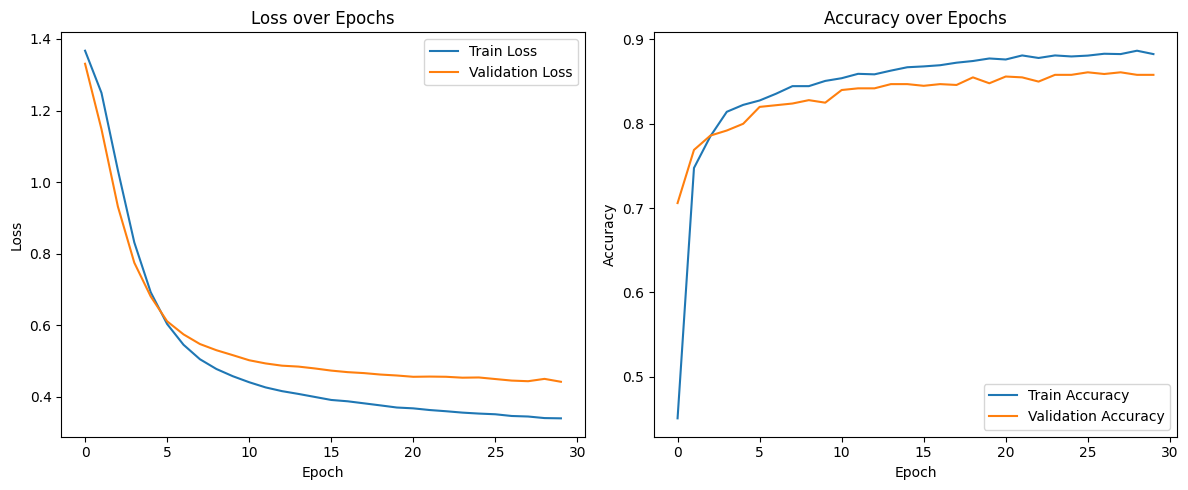

In [4]:
X_train_tensor = torch.tensor(X_train_embedded, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_test_tensor = torch.tensor(X_test_embedded, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

X_eval_tensor = torch.tensor(X_eval_embedded, dtype=torch.float32)
y_eval_tensor = torch.tensor(y_eval, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
eval_dataset = TensorDataset(X_eval_tensor, y_eval_tensor)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
eval_loader = DataLoader(eval_dataset, batch_size=batch_size, shuffle=False)

class NewsClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(NewsClassifier, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

input_dim = X_train_embedded.shape[1]  # 300
hidden_dim = 128
output_dim = len(np.unique(y_train))
model = NewsClassifier(input_dim, hidden_dim, output_dim).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
num_epochs = 30
train_losses = []
eval_losses = []
train_accuracies = []
eval_accuracies = []

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    all_train_preds = []
    all_train_labels = []
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        all_train_preds.extend(predicted.cpu().numpy())
        all_train_labels.extend(labels.cpu().numpy())

    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_accuracy = accuracy_score(all_train_labels, all_train_preds)
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_accuracy)
    model.eval()
    eval_running_loss = 0.0
    all_eval_preds = []
    all_eval_labels = []
    with torch.no_grad():
        for inputs, labels in eval_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            eval_running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            all_eval_preds.extend(predicted.cpu().numpy())
            all_eval_labels.extend(labels.cpu().numpy())

    epoch_eval_loss = eval_running_loss / len(eval_loader.dataset)
    epoch_eval_accuracy = accuracy_score(all_eval_labels, all_eval_preds)
    eval_losses.append(epoch_eval_loss)
    eval_accuracies.append(epoch_eval_accuracy)

    print(f'Epoch {epoch+1}/{num_epochs} - Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_accuracy:.4f}, Eval Loss: {epoch_eval_loss:.4f}, Eval Acc: {epoch_eval_accuracy:.4f}')

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(eval_losses, label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(eval_accuracies, label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

## Results Analysis

Evaluate the trained model on the test set, compute Accuracy, Macro-F1 score, and Confusion Matrix, analyze class-wise performance, and inspect misclassified text examples.

Test Accuracy: 87.40%
Test Macro-F1 Score: 87.37%






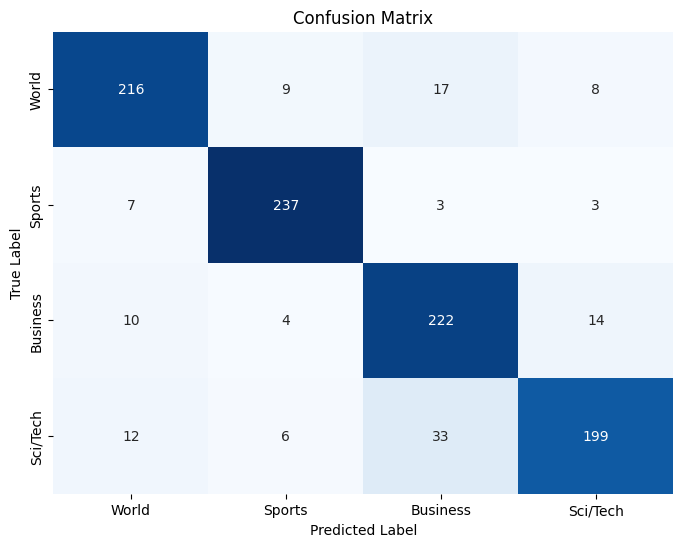

In [5]:
model.eval()
all_test_preds = []
all_test_labels = []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        all_test_preds.extend(predicted.cpu().numpy())
        all_test_labels.extend(labels.cpu().numpy())

accuracy = accuracy_score(all_test_labels, all_test_preds)
macro_f1 = f1_score(all_test_labels, all_test_preds, average='macro')
conf_matrix = confusion_matrix(all_test_labels, all_test_preds)

print(f"Test Accuracy: {accuracy*100:.2f}%")
print(f"Test Macro-F1 Score: {macro_f1*100:.2f}%")
print("\n\n\n")

class_names = ['World', 'Sports', 'Business', 'Sci/Tech']

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

num_classes = len(class_names)
class_accuracy = conf_matrix.diagonal() / conf_matrix.sum(axis=1)
precision, recall, f1, support = precision_recall_fscore_support(all_test_labels, all_test_preds, labels=np.arange(num_classes))

metrics_df = pd.DataFrame({
    'class_id': np.arange(num_classes),
    'class_name': class_names,
    'accuracy': class_accuracy,
    'precision': precision,
    'recall': recall,
    'f1': f1,
    'support': support
})

In [6]:
print("\n--- Class-wise Metrics ---")
print(metrics_df.to_string(index=False, float_format=lambda x: f"{x:0.4f}"))

print("\n--- Analysis of Model Performance ---")
print("Class-wise Accuracy:")
for i, acc in enumerate(class_accuracy):
    print(f"Class {i}: {acc:.4f}")

best_class = np.argmax(class_accuracy)
worst_class = np.argmin(class_accuracy)
print(f"Best performing class: Class {best_class} (Accuracy: {class_accuracy[best_class]:.4f})")
print(f"Worst performing class: Class {worst_class} (Accuracy: {class_accuracy[worst_class]:.4f})")

print("\nMost confused classes:")
for i in range(num_classes):
    for j in range(num_classes):
        if i != j and conf_matrix[i, j] > 0:
            print(f"  True Class {i} predicted as Class {j}: {conf_matrix[i, j]} instances")


--- Class-wise Metrics ---
 class_id class_name  accuracy  precision  recall     f1  support
        0      World    0.8640     0.8816  0.8640 0.8727      250
        1     Sports    0.9480     0.9258  0.9480 0.9368      250
        2   Business    0.8880     0.8073  0.8880 0.8457      250
        3   Sci/Tech    0.7960     0.8884  0.7960 0.8397      250

--- Analysis of Model Performance ---
Class-wise Accuracy:
Class 0: 0.8640
Class 1: 0.9480
Class 2: 0.8880
Class 3: 0.7960
Best performing class: Class 1 (Accuracy: 0.9480)
Worst performing class: Class 3 (Accuracy: 0.7960)

Most confused classes:
  True Class 0 predicted as Class 1: 9 instances
  True Class 0 predicted as Class 2: 17 instances
  True Class 0 predicted as Class 3: 8 instances
  True Class 1 predicted as Class 0: 7 instances
  True Class 1 predicted as Class 2: 3 instances
  True Class 1 predicted as Class 3: 3 instances
  True Class 2 predicted as Class 0: 10 instances
  True Class 2 predicted as Class 1: 4 instances

In [7]:
misclassified_indices = np.where(np.array(all_test_labels) != np.array(all_test_preds))[0]

print("\n--- Examples of Misclassified Texts ---")
print(f"Total misclassified samples: {len(misclassified_indices)}")

for i, idx in enumerate(misclassified_indices[:3]):
    original_text_idx = idx
    true_label = all_test_labels[idx]
    predicted_label = all_test_preds[idx]
    original_text = X_test[original_text_idx]

    print(f"\nSample {i+1} (Index in test set: {original_text_idx}):")
    print(f"  Original Text: {original_text[:200]}...")
    print(f"  True Label: {true_label} ({class_names[true_label]}) ")
    print(f"  Predicted Label: {predicted_label} ({class_names[predicted_label]}) ")


--- Examples of Misclassified Texts ---
Total misclassified samples: 126

Sample 1 (Index in test set: 10):
  Original Text: sc to hear zee petition tommorrow five judges of the top court will hear a petition filed by zee telefilms on tuesday. a three-judge panel of the supreme court said a five-judge bench would hear the d...
  True Label: 1 (Sports) 
  Predicted Label: 2 (Business) 

Sample 2 (Index in test set: 27):
  Original Text: hp to tempt holiday shoppers with sights and sounds the computer-hardware giant, best known for products such as pcs and printers, on friday laid out its plan to become a brand-name in consumer electr...
  True Label: 2 (Business) 
  Predicted Label: 3 (Sci/Tech) 

Sample 3 (Index in test set: 73):
  Original Text: disgraced greek sprinters drug tested by wada athens (reuters) - greek sprinters costas kenteris and katerina thanou have been dope tested by doctors from the world anti-doping agency, an official sai...
  True Label: 1 (Sports) 
  Predicted 